In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from keras import layers, models
from keras.datasets import cifar10
from keras.utils import to_categorical
from keras.optimizers import SGD

# Zadatak 1

## Preprocesiranje

In [20]:
(train_X, train_y), (test_X, test_y) = cifar10.load_data()

In [21]:
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)

(50000, 32, 32, 3) (50000, 1) (10000, 32, 32, 3) (10000, 1)


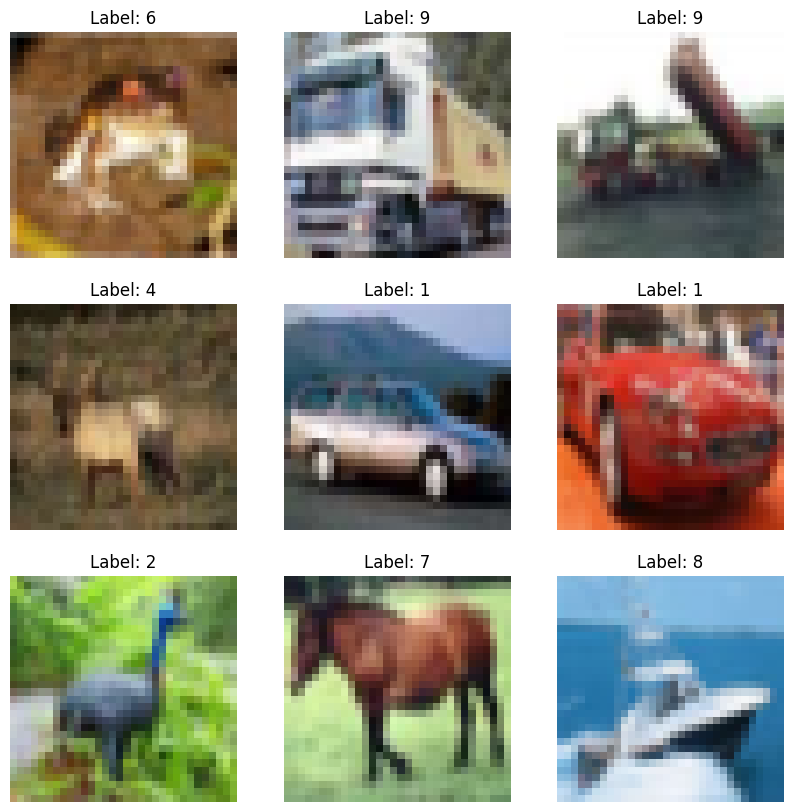

In [22]:
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(train_X[i])
    plt.title(f"Label: {train_y[i][0]}")
    plt.axis('off')
plt.show()

In [23]:
train_y = to_categorical(train_y, 10)
test_y = to_categorical(test_y, 10)

In [24]:
train_X = train_X.astype("float32") / 255.0
test_X = test_X.astype("float32") / 255.0

## Funkcije

In [25]:
def plot_loss_acc(history):
    acc = history.history["accuracy"]
    epochs = range(1, len(acc) + 1)

    loss_values = history.history["loss"]
    val_loss_values = history.history["val_loss"]

    plt.plot(epochs, loss_values, "bo", label="Training loss")
    plt.plot(epochs, val_loss_values, "b", label="Validation loss")
    plt.title("Training and validation loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

    plt.clf()

    acc_values = history.history["accuracy"]
    val_acc_values = history.history["val_accuracy"]

    plt.plot(epochs, acc_values, "bo", label="Training accuracy")
    plt.plot(epochs, val_acc_values, "b", label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

In [38]:
def define_model():
    model = models.Sequential()

    model.add(layers.InputLayer(shape=(32, 32, 3)))

    model.add(layers.Conv2D(32, (3, 3), padding="same"))
    model.add(layers.Conv2D(32, (3, 3), padding="same"))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.2))

    model.add(layers.Conv2D(64, (3, 3), padding="same"))
    model.add(layers.Conv2D(64, (3, 3), padding="same"))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.2))

    model.add(layers.Conv2D(128, (3, 3), padding="same"))
    model.add(layers.Conv2D(128, (3, 3), padding="same"))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.2))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dropout(0.2))
    model.add(layers.Dense(10, activation="softmax"))

    opt = SGD(learning_rate=0.001, momentum=0.9)

    model.compile(
        optimizer=opt,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

## Varijanta 1

In [28]:
model = define_model()

In [29]:
history = model.fit(
    train_X,
    train_y,
    epochs=15,
    batch_size=64,
    validation_data=(test_X, test_y)
)

Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.2525 - loss: 2.0509 - val_accuracy: 0.4349 - val_loss: 1.6166
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.4563 - loss: 1.5450 - val_accuracy: 0.5030 - val_loss: 1.4083
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5220 - loss: 1.3623 - val_accuracy: 0.5278 - val_loss: 1.3393
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5711 - loss: 1.2305 - val_accuracy: 0.5888 - val_loss: 1.1675
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6179 - loss: 1.1099 - val_accuracy: 0.6128 - val_loss: 1.1072
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6485 - loss: 1.0149 - val_accuracy: 0.6314 - val_loss: 1.0500
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6799 - loss: 0.9335 - val_accuracy: 0.6557 - val_loss: 1.0005
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7028 - loss: 0.8631 - val_accuracy: 0.

In [30]:
test_loss, test_acc = model.evaluate(test_X, test_y)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6987 - loss: 0.9693


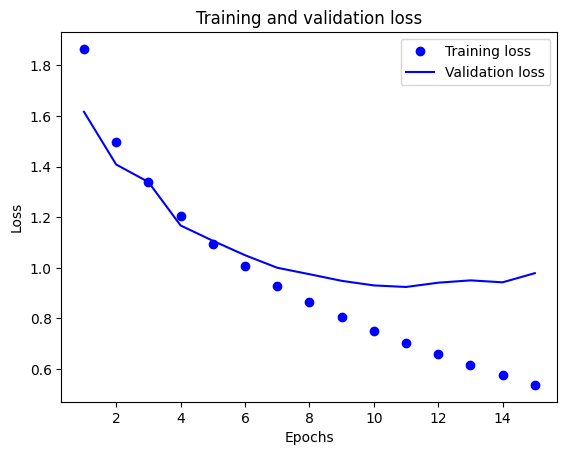

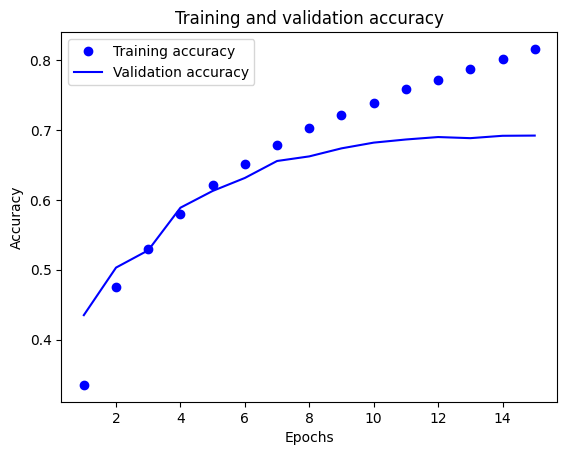

In [31]:
plot_loss_acc(history)

## Varijanta 2

In [34]:
model = define_model()

In [35]:
history = model.fit(
    train_X,
    train_y,
    epochs=15,
    batch_size=64,
    validation_data=(test_X, test_y)
)

Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.2321 - loss: 2.0912 - val_accuracy: 0.4276 - val_loss: 1.6279
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.4148 - loss: 1.6388 - val_accuracy: 0.4742 - val_loss: 1.4759
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4730 - loss: 1.4905 - val_accuracy: 0.5293 - val_loss: 1.3292
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5209 - loss: 1.3532 - val_accuracy: 0.5643 - val_loss: 1.2384
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.5548 - loss: 1.2645 - val_accuracy: 0.5895 - val_loss: 1.1725
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5852 - loss: 1.1873 - val_accuracy: 0.6118 - val_loss: 1.1023
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6062 - loss: 1.1262 - val_accuracy: 0.6356 - val_loss: 1.0515
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6299 - loss: 1.0620 - val_accuracy: 0.

In [36]:
test_loss, test_acc = model.evaluate(test_X, test_y)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7058 - loss: 0.8467


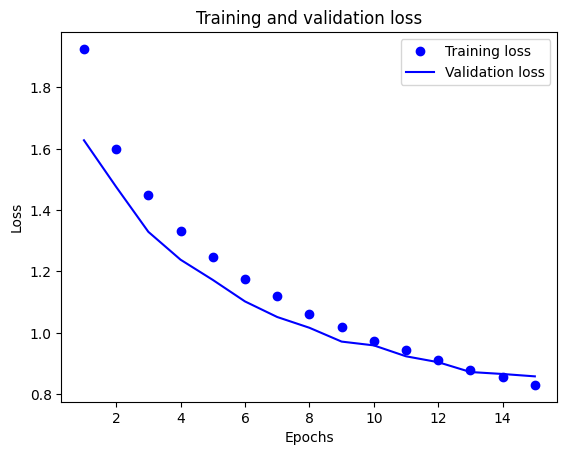

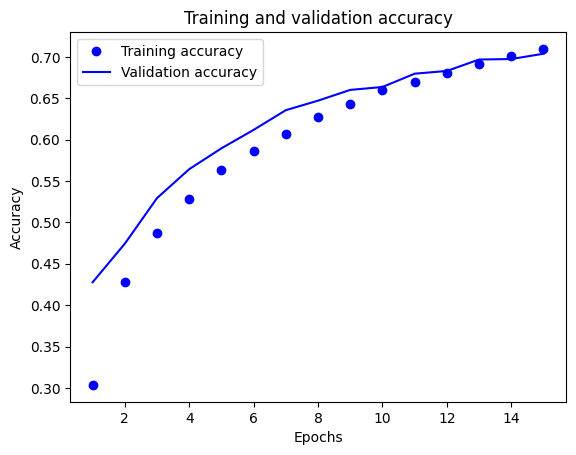

In [37]:
plot_loss_acc(history)

## Varijanta 3

In [39]:
model = define_model()

In [40]:
history = model.fit(
    train_X,
    train_y,
    epochs=30,
    batch_size=64,
    validation_data=(test_X, test_y)
)

Epoch 1/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.2059 - loss: 2.1360 - val_accuracy: 0.3950 - val_loss: 1.6973
Epoch 2/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.3955 - loss: 1.6932 - val_accuracy: 0.4607 - val_loss: 1.4953
Epoch 3/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.4545 - loss: 1.5199 - val_accuracy: 0.4893 - val_loss: 1.4397
Epoch 4/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.5011 - loss: 1.4022 - val_accuracy: 0.5594 - val_loss: 1.2521
Epoch 5/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.5397 - loss: 1.2955 - val_accuracy: 0.5820 - val_loss: 1.1884
Epoch 6/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.5665 - loss: 1.2160 - val_accuracy: 0.5815 - val_loss: 1.1743
Epoch 7/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5924 - loss: 1.1561 - val_accuracy: 0.6216 - val_loss: 1.0756
Epoch 8/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6140 - loss: 1.0969 - val_accu

In [41]:
test_loss, test_acc = model.evaluate(test_X, test_y)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7701 - loss: 0.6747


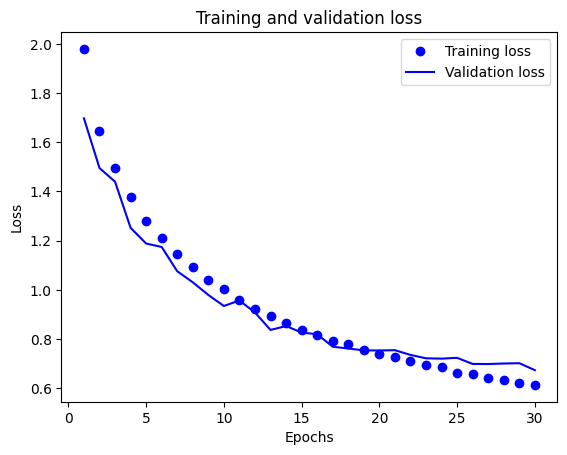

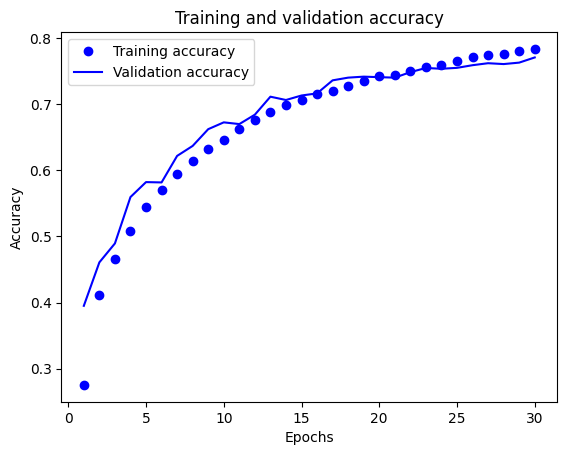

In [42]:
plot_loss_acc(history)